Step 1: Load the dataset again

In [2]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

# Load dataset
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Target distribution:")
print(y.value_counts().sort_index())

Dataset shape: (569, 30)
Target distribution:
target
0    212
1    357
Name: count, dtype: int64


## 1. Train-Test Split

### What is it?
Train-test splitting divides the dataset into two parts: training data for learning and testing data for evaluating the model on unseen samples.

### Why do we need it?
If we evaluate a model on the same data it learned from, its performance may look better than it really is. Testing on separate samples helps us estimate how well it generalizes to new data.

### Our approach
- Total samples: 569
- Training data: 80% (455 samples)
- Testing data: 20% (114 samples)
- `random_state=42`: Makes the split reproducible.
- `stratify=y`: Preserves approximately the original proportion of benign and malignant cases.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


## 2. Understanding Feature Scaling

### What is feature scaling?
Feature scaling adjusts numerical features to comparable scales while preserving their relative information.

### Why is it useful?
Our dataset contains measurements with different ranges. For example, tumor area has much larger numerical values than smoothness. Algorithms such as Logistic Regression and SVM can be sensitive to these differences.

### Which models need it?
- Logistic Regression: Usually benefits from scaling.
- SVM: Usually benefits from scaling.
- Decision Tree: Generally does not require scaling.
- Random Forest: Generally does not require scaling.
- XGBoost: Generally does not require scaling.

### Important rule
Fit the scaler using training data only, then apply the same transformation to the test data. This prevents test-set information from influencing preprocessing.

In [5]:
X_train.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
546,10.32,16.35,65.31,324.9,0.09434,0.04994,0.01012,0.005495,0.1885,0.06201,...,11.25,21.77,71.12,384.9,0.1285,0.08842,0.04384,0.02381,0.2681,0.07399
432,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,0.1724,0.06053,...,22.03,25.07,146.00,1479.0,0.1665,0.29420,0.53080,0.21730,0.3032,0.08075
174,10.66,15.15,67.49,349.6,0.08792,0.04302,0.00000,0.000000,0.1928,0.05975,...,11.54,19.20,73.20,408.3,0.1076,0.06791,0.00000,0.00000,0.2710,0.06164
221,13.56,13.90,88.59,561.3,0.10510,0.11920,0.07860,0.044510,0.1962,0.06303,...,14.98,17.13,101.10,686.6,0.1376,0.26980,0.25770,0.09090,0.3065,0.08177
289,11.37,18.89,72.17,396.0,0.08713,0.05008,0.02399,0.021730,0.2013,0.05955,...,12.36,26.14,79.29,459.3,0.1118,0.09708,0.07529,0.06203,0.3267,0.06994


In [6]:
# Compare the minimum and maximum values of selected features
X_train[["mean radius", "mean area", "mean smoothness"]].agg(
    ["min", "max"]
)

,mean radius,mean area,mean smoothness
min,6.981,143.5,0.06251
max,28.110,2499.0,0.14470


## 2. Feature Scaling — Standardization

### What is standardization?
Standardization converts numerical features into values based on their distance from the feature's mean, measured in standard deviations.

### Formula
z = (x - mean) / standard deviation

In [7]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn the scaling values from training data
X_train_scaled = scaler.fit_transform(X_train)

print("Original training data:")
print(X_train.iloc[:5, :3])

print("\nScaled training data:")
print(X_train_scaled[:5, :3])

Original training data:
     mean radius  mean texture  mean perimeter
546        10.32         16.35           65.31
432        20.18         19.54          133.80
174        10.66         15.15           67.49
221        13.56         13.90           88.59
289        11.37         18.89           72.17

Scaled training data:
[[-1.07200079 -0.6584246  -1.0880801 ]
 [ 1.74874285  0.06650173  1.75115682]
 [-0.97473376 -0.93112416 -0.99770871]
 [-0.14510328 -1.2151862  -0.12301315]
 [-0.77161734 -0.08121053 -0.8037004 ]]


### Understanding the Scaled Output

- StandardScaler transforms features using the training-data mean and standard deviation.
- Negative values indicate measurements below the training-data mean.
- Positive values indicate measurements above the training-data mean.
- Values near zero indicate measurements close to the mean.
- Scaling changes the numerical representation, not the original sample or its diagnosis.

**Important:** In the final experiment, scaling will be fitted on training data only. We'll use a pipeline for models that need scaling, such as Logistic Regression and SVM.

## 3. Model 1 — Logistic Regression

### What is Logistic Regression?
Logistic Regression is a supervised machine learning algorithm used for classification. It learns relationships between input features and known class labels.

### How does it work?
It combines the input features into a score and converts that score into an estimated probability for a class. The model then uses a decision threshold to assign a predicted class.

### Our implementation
We use a pipeline containing StandardScaler and LogisticRegression. The scaler learns from the training data, and Logistic Regression learns from the scaled measurements and their labels.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the model pipeline
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


## Making Predictions with Logistic Regression

### What is prediction?
After training, the model uses the patterns it learned to predict labels for new samples.

### Our approach
We use `logistic_model.predict(X_test)` to predict the diagnosis for the 114 testing samples.

### Understanding the labels
- `0`: Malignant
- `1`: Benign

### Why use test data?
The model did not train on these samples, so they help us evaluate how well it generalizes to unseen data.

### Important error
A false negative occurs when the actual class is malignant (`0`) but the model predicts benign (`1`). We will examine this type of error carefully because missing a malignant case matters in a medical prediction setting.

In [9]:
# Predict the diagnosis for the test samples
y_pred = logistic_model.predict(X_test)

# Display the first 10 predictions
print("Predicted labels:")
print(y_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())

Predicted labels:
[0 1 0 1 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [10]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.9824561403508771
Accuracy percentage: 98.25 %


## Logistic Regression — Initial Accuracy Result
- Test samples: 114
- Accuracy: 98.25%
- Correct predictions: 112
- Incorrect predictions: 2

### Interpretation
The model correctly classified approximately 98.25% of the held-out test samples.

### Limitation
Accuracy alone does not reveal which types of classification errors occurred. For disease prediction, we must pay particular attention to malignant cases incorrectly classified as benign.

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[41  1]
 [ 1 71]]


- 41 — Correct malignant predictions: Of the samples that were actually malignant, the model correctly identified 41 as malignant.
- 1 — Missed malignant case: One malignant sample was incorrectly predicted as benign. This is a false negative.
- 1 — Benign sample incorrectly flagged: One benign sample was incorrectly predicted as malignant. This is a false positive.
- 71 — Correct benign predictions: The model correctly identified 71 benign samples.

Check the total: 41+1+1+71=114.

In [12]:
from sklearn.metrics import precision_score, recall_score

# Treat malignant (label 0) as the positive class
precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)

# Scikit-learn normally treats label 1 as the positive class. But in our project, we want to focus specifically on malignant cases, which are labelled 0. This argument makes the calculation match our goal.
# We use pos_label=0 because malignant is encoded as 0 in this dataset.

print("Malignant Precision:", round(precision * 100, 2), "%")
print("Malignant Recall:", round(recall * 100, 2), "%")

Malignant Precision: 97.62 %
Malignant Recall: 97.62 %


In [13]:
from sklearn.metrics import f1_score

# Evaluate the malignant class (label 0)
f1 = f1_score(y_test, y_pred, pos_label=0)

print("Malignant F1-score:", round(f1 * 100, 2), "%")

Malignant F1-score: 97.62 %


## F1-Score

### What is F1-score?
F1-score combines Precision and Recall into a single metric using their harmonic mean.

### Formula
F1 = 2 × (Precision × Recall) / (Precision + Recall)

### Why do we use it?
A high F1-score indicates that both Precision and Recall are high. It is useful when we want to balance the reliability of positive predictions with the ability to find positive cases.

In [14]:
from sklearn.metrics import roc_auc_score

# Get the predicted probability for each class
y_prob = logistic_model.predict_proba(X_test)

# Column 0 represents malignant (label 0)
malignant_prob = y_prob[:, 0]

# Calculate ROC-AUC for malignant cases
roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    malignant_prob
)

print("Malignant ROC-AUC:", round(roc_auc, 4))

Malignant ROC-AUC: 0.9954


### What is ROC-AUC?
ROC-AUC measures how well a classification model distinguishes between classes across different decision thresholds.

### Why do we use it?
Accuracy, Precision, Recall, and F1-score evaluate predictions at a particular threshold. ROC-AUC evaluates how well the model ranks samples across thresholds.

### Interpretation
- AUC = 1.0: Perfect ranking on the evaluated data.
- AUC = 0.5: Random-level ranking.
- Higher AUC: Better class separation.

### Current Logistic Regression results
Accuracy: 98.25%
Malignant Precision: 97.62%
Malignant Recall: 97.62%
Malignant F1-score: 97.62%
Malignant ROC-AUC: 0.9954

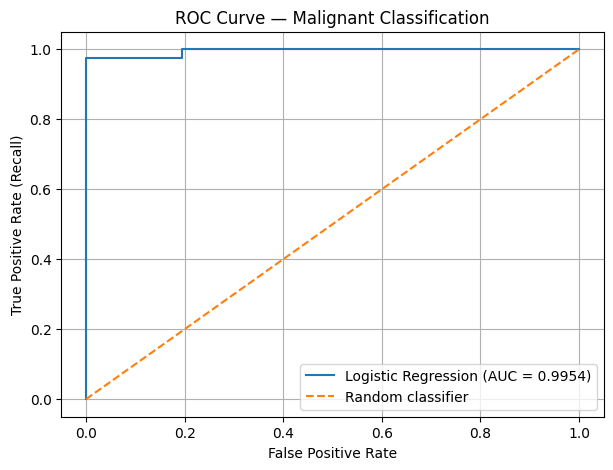

In [15]:
# Visualize the ROC curve

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(
    (y_test == 0).astype(int),
    malignant_prob
)

# Plot the ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Malignant Classification")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Model 2 — Decision Tree

### What is a Decision Tree?
A Decision Tree is a supervised machine learning algorithm that learns a sequence of rules to classify samples.

### How does it work?
It selects feature-based questions and thresholds that divide the training samples into groups. Following these rules leads to a predicted class.

### Why are we using it?
Decision Trees are easy to visualize and can capture nonlinear relationships without requiring feature scaling.

### Limitation
A tree that grows too deep can memorize training data and perform poorly on unseen samples. This is called overfitting.

In [17]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree
tree_model = DecisionTreeClassifier(random_state=42)

# Train it using the training data
tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [18]:
# Make predictions using the Decision Tree
tree_pred = tree_model.predict(X_test)

print("First 10 Decision Tree predictions:")
print(tree_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())


First 10 Decision Tree predictions:
[0 1 0 1 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [19]:
from sklearn.metrics import accuracy_score
tree_accuracy = accuracy_score(y_test, tree_pred)
print("Decision Tree Accuracy:", round(tree_accuracy * 100, 2), "%")

Decision Tree Accuracy: 91.23 %


In [20]:

from sklearn.metrics import confusion_matrix

tree_cm = confusion_matrix(y_test, tree_pred)

print("Decision Tree Confusion Matrix:")
print(tree_cm)


Decision Tree Confusion Matrix:
[[39  3]
 [ 7 65]]


In [21]:
from sklearn.metrics import precision_score, recall_score
tree_precision = precision_score(
    y_test, tree_pred, pos_label=0
)

tree_recall = recall_score(
    y_test, tree_pred, pos_label=0
)

print("Malignant Precision:", round(tree_precision * 100, 2), "%")
print("Malignant Recall:", round(tree_recall * 100, 2), "%")


Malignant Precision: 84.78 %
Malignant Recall: 92.86 %


In [22]:
from sklearn.metrics import f1_score
tree_f1 = f1_score(y_test, tree_pred, pos_label=0)

print("Malignant F1-score:", round(tree_f1 * 100, 2), "%")

Malignant F1-score: 88.64 %


In [23]:
from sklearn.metrics import roc_auc_score

# Get predicted probabilities for each class
tree_prob = tree_model.predict_proba(X_test)

# Column 0 contains the probability of malignant (class 0)
tree_malignant_prob = tree_prob[:, 0]

# Calculate ROC-AUC for malignant classification
tree_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    tree_malignant_prob
)

print("Decision Tree Malignant ROC-AUC:", round(tree_roc_auc, 4))

Decision Tree Malignant ROC-AUC: 0.9157


## Decision Tree — Baseline Evaluation

**Model:** `DecisionTreeClassifier(random_state=42)`

**Dataset:** Breast Cancer Wisconsin (Diagnostic)

**Training samples:** 455

**Testing samples:** 114

### Evaluation Results

- Accuracy: 91.23%
- Malignant precision: 84.78%
- Malignant recall: 92.86%
- Malignant F1-score: 88.64%
- Malignant ROC-AUC: 0.9157

### Confusion Matrix

`[[39, 3], [7, 65]]`

- 39 malignant cases correctly identified.
- 3 malignant cases incorrectly classified as benign.
- 7 benign cases incorrectly classified as malignant.
- 65 benign cases correctly identified.

### Interpretation

The Decision Tree achieved 91.23% accuracy on the test set. Its malignant recall was higher than its malignant precision, indicating that it identified most malignant cases but also incorrectly flagged some benign cases.

Logistic Regression performed better across the evaluated metrics on this test split. Further experiments and cross-validation are needed to assess model stability.

## Random Forest — Model Training

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

- Number of trees: 100
- Random state: 42
- Training data: 455 samples
- Test data: 114 samples

The model combines the outputs of multiple trees to make a final classification. We will evaluate it using the same test set as Logistic Regression and Decision Tree.

In [24]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
# n_estimators=100: creates a forest containing 100 decision trees.
# Train the model using the training data
forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [25]:
# Make predictions using Random Forest
forest_pred = forest_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(forest_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())

First 10 Random Forest predictions:
[0 1 0 0 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [26]:
from sklearn.metrics import accuracy_score

forest_accuracy = accuracy_score(y_test, forest_pred)

print("Random Forest Accuracy:", round(forest_accuracy * 100, 2), "%")


Random Forest Accuracy: 95.61 %


In [27]:
from sklearn.metrics import confusion_matrix
forest_cm = confusion_matrix(y_test, forest_pred)

print("Random Forest Confusion Matrix:")
print(forest_cm)

Random Forest Confusion Matrix:
[[39  3]
 [ 2 70]]


In [28]:
from sklearn.metrics import precision_score, recall_score

forest_precision = precision_score(
    y_test, forest_pred, pos_label=0
)

forest_recall = recall_score(
    y_test, forest_pred, pos_label=0
)

print("Malignant Precision:", round(forest_precision * 100, 2), "%")
print("Malignant Recall:", round(forest_recall * 100, 2), "%")

Malignant Precision: 95.12 %
Malignant Recall: 92.86 %


In [29]:
from sklearn.metrics import f1_score

forest_f1 = f1_score(y_test, forest_pred, pos_label=0)

print("Malignant F1-score:", round(forest_f1 * 100, 2), "%")


Malignant F1-score: 93.98 %


In [30]:
from sklearn.metrics import roc_auc_score

# Get predicted probabilities for both classes
forest_prob = forest_model.predict_proba(X_test)

# Select the probability of malignant (class 0)
forest_malignant_prob = forest_prob[:, 0]

# Calculate ROC-AUC
forest_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    forest_malignant_prob
)

print("Random Forest Malignant ROC-AUC:", round(forest_roc_auc, 4))

Random Forest Malignant ROC-AUC: 0.9937


## Random Forest — Baseline Evaluation

**Model:** `RandomForestClassifier(n_estimators=100, random_state=42)`

**Dataset:** Breast Cancer Wisconsin (Diagnostic)

**Training samples:** 455

**Testing samples:** 114

### Evaluation Results

- Accuracy: 95.61%
- Malignant precision: 95.12%
- Malignant recall: 92.86%
- Malignant F1-score: 93.98%
- Malignant ROC-AUC: 0.9937

### Confusion Matrix

`[[39, 3], [2, 70]]`

- 39 malignant cases correctly identified.
- 3 malignant cases incorrectly classified as benign.
- 2 benign cases incorrectly classified as malignant.
- 70 benign cases correctly identified.

### Interpretation

Random Forest combines multiple decision trees to make predictions. It achieved higher accuracy, precision, F1-score, and ROC-AUC than the single Decision Tree on this test split.

Logistic Regression remains the strongest of the three models across the evaluated metrics on this split.

## Support Vector Machine (SVM) — Model Setup

SVM is a supervised machine learning algorithm that classifies samples by learning a decision boundary between classes.

- Kernel: Linear
- Preprocessing: StandardScaler
- Probability estimates: Enabled
- Training data: `X_train`, `y_train`
- Test data: `X_test`, `y_test`

A pipeline combines feature scaling and classification so that the scaler is fitted only on the training data.

In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create the SVM model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", probability=True, random_state=42)
)

print("SVM model created successfully!")


SVM model created successfully!


In [32]:
# Train the SVM model
svm_model.fit(X_train, y_train)

print("SVM training completed!")


SVM training completed!


In [33]:
# Make predictions using SVM
svm_pred = svm_model.predict(X_test)

print("First 10 SVM predictions:")
print(svm_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())


First 10 SVM predictions:
[0 1 0 0 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [34]:
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

SVM Accuracy: 97.37 %


In [35]:
from sklearn.metrics import confusion_matrix
svm_cm = confusion_matrix(y_test, svm_pred)

print("SVM Confusion Matrix:")
print(svm_cm)


SVM Confusion Matrix:
[[41  1]
 [ 2 70]]


In [36]:
from sklearn.metrics import precision_score, recall_score

svm_precision = precision_score(
    y_test, svm_pred, pos_label=0
)

svm_recall = recall_score(
    y_test, svm_pred, pos_label=0
)

print("Malignant Precision:", round(svm_precision * 100, 2), "%")
print("Malignant Recall:", round(svm_recall * 100, 2), "%")

Malignant Precision: 95.35 %
Malignant Recall: 97.62 %


In [37]:
from sklearn.metrics import f1_score

svm_f1 = f1_score(y_test, svm_pred, pos_label=0)

print("Malignant F1-score:", round(svm_f1 * 100, 2), "%")


Malignant F1-score: 96.47 %


In [38]:
from sklearn.metrics import roc_auc_score

# Get predicted probabilities for both classes
svm_prob = svm_model.predict_proba(X_test)

# Select the probability of malignant (class 0)
svm_malignant_prob = svm_prob[:, 0]

# Calculate ROC-AUC
svm_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    svm_malignant_prob
)

print("SVM Malignant ROC-AUC:", round(svm_roc_auc, 4))


SVM Malignant ROC-AUC: 0.9964


## Support Vector Machine (SVM) — Baseline Evaluation

**Model:** `SVC(kernel="linear", probability=True, random_state=42)`

**Preprocessing:** `StandardScaler()` inside a pipeline

**Training samples:** 455

**Testing samples:** 114

### Evaluation Results

- Accuracy: 97.37%
- Malignant precision: 95.35%
- Malignant recall: 97.62%
- Malignant F1-score: 96.47%
- Malignant ROC-AUC: 0.9964

### Confusion Matrix

`[[41, 1], [2, 70]]`

- 41 malignant cases correctly identified.
- 1 malignant case incorrectly classified as benign.
- 2 benign cases incorrectly classified as malignant.
- 70 benign cases correctly identified.

### Interpretation

The linear SVM achieved 97.37% accuracy and 97.62% malignant recall on the test set. It missed one malignant sample and incorrectly classified two benign samples as malignant.

Its ROC-AUC was the highest among the four baseline models evaluated so far. Logistic Regression still achieved higher accuracy and malignant F1-score.

## K-Nearest Neighbors (KNN) — Model Setup

KNN classifies a sample by examining the labels of its nearest training samples.

- Number of neighbors: 5
- Preprocessing: StandardScaler
- Training data: `X_train`, `y_train`
- Test data: `X_test`, `y_test`

Feature scaling is important because KNN uses distances to identify similar samples. The scaler is included in a pipeline to prevent data leakage.

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

print("KNN model created successfully!")


KNN model created successfully!


In [40]:
# Train the KNN model
knn_model.fit(X_train, y_train)

print("KNN training completed!")


KNN training completed!


In [41]:
# Make predictions using KNN
knn_pred = knn_model.predict(X_test)

print("First 10 KNN predictions:")
print(knn_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())


First 10 KNN predictions:
[0 1 0 0 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


c:\Users\Kasyap\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Kasyap\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Kasyap\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Kasyap\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Kasyap\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

This is a warning, not a model-training error. Your predictions were generated successfully.

The warning means that a background library couldn't determine the number of physical CPU cores on your Windows system, so it fell back to counting logical cores. You can ignore it for now; it doesn't change the predictions you've already obtained.

In [42]:
from sklearn.metrics import accuracy_score
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")


KNN Accuracy: 95.61 %


In [43]:
from sklearn.metrics import confusion_matrix

knn_cm = confusion_matrix(y_test, knn_pred)

print("KNN Confusion Matrix:")
print(knn_cm)


KNN Confusion Matrix:
[[39  3]
 [ 2 70]]


In [44]:
from sklearn.metrics import precision_score, recall_score

knn_precision = precision_score(
    y_test, knn_pred, pos_label=0
)

knn_recall = recall_score(
    y_test, knn_pred, pos_label=0
)

print("Malignant Precision:", round(knn_precision * 100, 2), "%")
print("Malignant Recall:", round(knn_recall * 100, 2), "%")


Malignant Precision: 95.12 %
Malignant Recall: 92.86 %


In [45]:
from sklearn.metrics import f1_score

knn_f1 = f1_score(y_test, knn_pred, pos_label=0)

print("Malignant F1-score:", round(knn_f1 * 100, 2), "%")


Malignant F1-score: 93.98 %


In [46]:
from sklearn.metrics import roc_auc_score

# Get predicted probabilities for both classes
knn_prob = knn_model.predict_proba(X_test)

# Select the probability of malignant (class 0)
knn_malignant_prob = knn_prob[:, 0]

# Calculate ROC-AUC
knn_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    knn_malignant_prob
)

print("KNN Malignant ROC-AUC:", round(knn_roc_auc, 4))


KNN Malignant ROC-AUC: 0.9788


## K-Nearest Neighbors (KNN) — Baseline Evaluation

**Model:** `KNeighborsClassifier(n_neighbors=5)`

**Preprocessing:** `StandardScaler()` inside a pipeline

**Training samples:** 455

**Testing samples:** 114

### Evaluation Results

- Accuracy: 95.61%
- Malignant precision: 95.12%
- Malignant recall: 92.86%
- Malignant F1-score: 93.98%
- Malignant ROC-AUC: 0.9788

### Confusion Matrix

`[[39, 3], [2, 70]]`

- 39 malignant cases correctly identified.
- 3 malignant cases incorrectly classified as benign.
- 2 benign cases incorrectly classified as malignant.
- 70 benign cases correctly identified.

### Interpretation

KNN classifies samples by examining their five nearest training examples. It achieved 95.61% accuracy and 92.86% malignant recall on this test split.

Its classification metrics matched those of Random Forest, but its ROC-AUC was lower. This demonstrates that models can produce the same hard classifications while assigning different probability estimates.

## Gaussian Naive Bayes

Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem.

It estimates class probabilities using the observed features and assumes that each feature follows a Gaussian distribution within each class.

- Model: `GaussianNB()`
- Feature scaling: Not required for this experiment
- Training data: `X_train`, `y_train`
- Test data: `X_test`, `y_test`

The model will predict malignant (`0`) or benign (`1`).

In [48]:
from sklearn.naive_bayes import GaussianNB

# Create the Naive Bayes model
nb_model = GaussianNB()

print("Naive Bayes model created successfully!")


Naive Bayes model created successfully!


In [49]:
# Train the Naive Bayes model
nb_model.fit(X_train, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [50]:
# Make predictions using Naive Bayes
nb_pred = nb_model.predict(X_test)

print("First 10 Naive Bayes predictions:")
print(nb_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].to_numpy())

First 10 Naive Bayes predictions:
[0 1 0 1 0 1 1 0 0 0]

Actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [51]:
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 93.86 %


In [52]:
from sklearn.metrics import confusion_matrix

nb_cm = confusion_matrix(y_test, nb_pred)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[38  4]
 [ 3 69]]


In [53]:
from sklearn.metrics import precision_score, recall_score

nb_precision = precision_score(
    y_test, nb_pred, pos_label=0
)

nb_recall = recall_score(
    y_test, nb_pred, pos_label=0
)

print("Malignant Precision:", round(nb_precision * 100, 2), "%")
print("Malignant Recall:", round(nb_recall * 100, 2), "%")

Malignant Precision: 92.68 %
Malignant Recall: 90.48 %


In [54]:
from sklearn.metrics import f1_score

nb_f1 = f1_score(y_test, nb_pred, pos_label=0)

print("Malignant F1-score:", round(nb_f1 * 100, 2), "%")

Malignant F1-score: 91.57 %


In [55]:
from sklearn.metrics import roc_auc_score

# Get predicted probabilities for both classes
nb_prob = nb_model.predict_proba(X_test)

# Select the probability of malignant (class 0)
nb_malignant_prob = nb_prob[:, 0]

# Calculate ROC-AUC
nb_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    nb_malignant_prob
)

print("Naive Bayes Malignant ROC-AUC:", round(nb_roc_auc, 4))

Naive Bayes Malignant ROC-AUC: 0.9878


## Gaussian Naive Bayes — Baseline Evaluation

**Model:** `GaussianNB()`

**Training samples:** 455

**Testing samples:** 114

### Evaluation Results

- Accuracy: 93.86%
- Malignant precision: 92.68%
- Malignant recall: 90.48%
- Malignant F1-score: 91.57%
- Malignant ROC-AUC: 0.9878

### Confusion Matrix

`[[38, 4], [3, 69]]`

- 38 malignant cases correctly identified.
- 4 malignant cases incorrectly classified as benign.
- 3 benign cases incorrectly classified as malignant.
- 69 benign cases correctly identified.

### Interpretation

Gaussian Naive Bayes uses Bayes' theorem and models each feature with a Gaussian distribution within each class. It achieved 93.86% accuracy and 90.48% malignant recall on this test split.

Its ROC-AUC was high despite lower accuracy, illustrating that ranking ability and classification accuracy measure different aspects of performance.

### XGBoost — Model Setup

- XGBoost is an ensemble learning algorithm based on decision trees.
- It builds trees sequentially, with each new tree helping correct errors made by previous trees.
- `n_estimators=100`: Number of boosting trees.
- `max_depth=3`: Maximum depth of each tree.
- `learning_rate=0.1`: Controls each tree's contribution.
- `random_state=42`: Helps make results reproducible.
- `eval_metric="logloss"`: Specifies the probability-based loss metric used during training.

In [56]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [57]:
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [58]:
y_pred_xgb = xgb_model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_xgb[:10])

First 10 actual labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 predicted labels:
[0 1 0 0 0 1 1 0 0 0]


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred_xgb)

# Evaluate class 0: malignant
malignant_precision = precision_score(y_test, y_pred_xgb, pos_label=0)
malignant_recall = recall_score(y_test, y_pred_xgb, pos_label=0)
malignant_f1 = f1_score(y_test, y_pred_xgb, pos_label=0)

# Calculate ROC-AUC for malignant class
malignant_probabilities = xgb_model.predict_proba(X_test)[:, 0]
actual_malignant = (y_test == 0).astype(int)

roc_auc = roc_auc_score(actual_malignant, malignant_probabilities)

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Malignant Precision: {malignant_precision:.4f}")
print(f"Malignant Recall: {malignant_recall:.4f}")
print(f"Malignant F1-Score: {malignant_f1:.4f}")
print(f"Malignant ROC-AUC: {roc_auc:.4f}")

Accuracy: 0.9474 (94.74%)
Malignant Precision: 0.9500
Malignant Recall: 0.9048
Malignant F1-Score: 0.9268
Malignant ROC-AUC: 0.9934


XGBoost Confusion Matrix:
[[38  4]
 [ 2 70]]


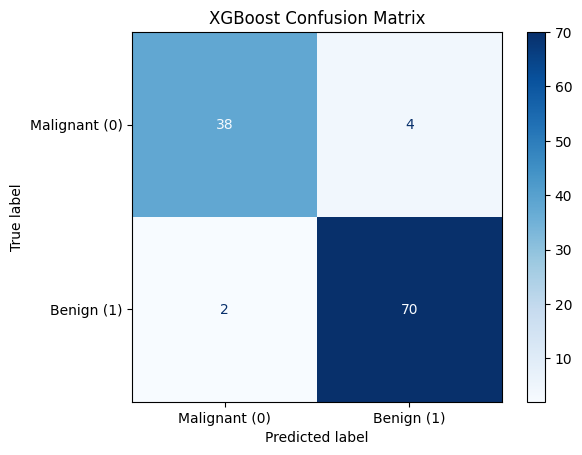

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=[0, 1])

print("XGBoost Confusion Matrix:")
print(cm_xgb)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Malignant (0)", "Benign (1)"]
)

display.plot(cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.show()

### XGBoost Classifier — Results and Analysis

**Model:** XGBoost Classifier

**Dataset:** Breast Cancer Wisconsin (Diagnostic)

**Test samples:** 114

**Evaluation Metrics:**
- Accuracy: 94.74%
- Malignant Precision: 95.00%
- Malignant Recall: 90.48%
- Malignant F1-score: 92.68%
- Malignant ROC-AUC: 0.9934

**Confusion Matrix:**

`[[38, 4], [2, 70]]`

**Observations:**

- The model correctly classified 108 out of 114 test samples.
- It correctly identified 38 malignant cases and 70 benign cases.
- It incorrectly classified 4 malignant cases as benign.
- It incorrectly classified 2 benign cases as malignant.
- Its malignant precision was high, but it did not identify every malignant case.
- The ROC-AUC score indicates strong class-ranking performance on this test set.

**Conclusion:**

XGBoost achieved good overall classification performance, with 94.74% accuracy and a 0.9934 ROC-AUC score. Its results can be compared with the other baseline models to understand the strengths and weaknesses of each algorithm.

### Comparing Seven Baseline Models

We compare Logistic Regression, Decision Tree, Random Forest, SVM, KNN, Naive Bayes, and XGBoost on the same test split.

Metrics:
- Accuracy measures overall correctness.
- Malignant precision measures the reliability of malignant predictions.
- Malignant recall measures how many actual malignant cases were identified.
- F1-score balances precision and recall.
- ROC-AUC measures how well the model ranks the two classes using predicted probabilities.

In [61]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN",
        "Naive Bayes",
        "XGBoost"
    ],
    "Accuracy (%)": [
        98.25, 91.23, 95.61, 97.37, 95.61, 93.86, 94.74
    ],
    "Malignant Precision (%)": [
        97.62, 84.78, 95.12, 95.35, 95.12, 92.68, 95.00
    ],
    "Malignant Recall (%)": [
        97.62, 92.86, 92.86, 97.62, 92.86, 90.48, 90.48
    ],
    "F1-Score (%)": [
        97.62, 88.64, 93.98, 96.47, 93.98, 91.57, 92.68
    ],
    "ROC-AUC": [
        0.9954, 0.9157, 0.9937, 0.9964, 0.9788, 0.9878, 0.9934
    ]
})

model_comparison

,Model,Accuracy (%),Malignant Precision (%),Malignant Recall (%),F1-Score (%),ROC-AUC
0,Logistic Regression,98.25,97.62,97.62,97.62,0.9954
1,Decision Tree,91.23,84.78,92.86,88.64,0.9157
2,Random Forest,95.61,95.12,92.86,93.98,0.9937
3,SVM,97.37,95.35,97.62,96.47,0.9964
4,KNN,95.61,95.12,92.86,93.98,0.9788
5,Naive Bayes,93.86,92.68,90.48,91.57,0.9878
6,XGBoost,94.74,95.00,90.48,92.68,0.9934


### Comparison of Seven Baseline Models

All seven models were evaluated using the same train/test split.

**Key findings:**

- Logistic Regression achieved the highest accuracy at 98.25%.
- Logistic Regression and SVM achieved the highest malignant recall at 97.62%.
- SVM achieved the highest ROC-AUC at 0.9964.
- Decision Tree had the lowest accuracy at 91.23%.
- XGBoost achieved 94.74% accuracy and 90.48% malignant recall.

**Conclusion:**

Logistic Regression performed best in accuracy and tied with SVM for malignant recall. SVM achieved the highest ROC-AUC. These results suggest that simpler models can perform very well on this dataset, and that model selection should consider multiple metrics rather than accuracy alone.

The results are based on one test split and are for educational comparison, not clinical diagnosis.